# 02 · Leakage and feature selection

The single most common mistake in Lending Club projects is **data leakage**: using information the lender didn't have when the customer applied.
This notebook shows what leakage does to results, then picks the features the PD model is allowed to use and looks at each one on its own.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from creditrisk import config
from creditrisk.data import load_processed, make_splits
from creditrisk.evaluation import default_rate_by
from creditrisk.features import (
    CATEGORICAL_FEATURES, LEAKAGE_COLUMNS, MODEL_FEATURES, NUMERIC_FEATURES,
    PRICING_COLUMNS, assert_no_leakage,
)

pd.set_option("display.float_format", "{:,.4f}".format)
df = load_processed()
splits = make_splits(df)
train, oot = splits["train"], splits["oot"]

## A deliberately broken model

Here's a model built from columns that are only known **after** the loan has run: how much principal was repaid, whether there were recoveries, and the borrower's latest credit score.

In [2]:
def leaky_features(d: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "share_principal_repaid": d["total_rec_prncp"] / d["funded_amnt"],
        "any_recoveries": (d["recoveries"] > 0).astype(int),
        "last_fico": d["last_fico_range_high"],
    }).fillna(0)

leaky_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
leaky_model.fit(leaky_features(train), train["default"])
leaky_auc = roc_auc_score(oot["default"], leaky_model.predict_proba(leaky_features(oot))[:, 1])
print(f"Out-of-time AUC of the leaky model: {leaky_auc:.3f}")

Out-of-time AUC of the leaky model: 1.000


An AUC close to 1 looks amazing and is **completely useless**: at the moment someone applies, nobody knows how much principal they'll repay.
The model is reading the answer, not predicting it.

**Rule of thumb:** if a credit model scores near-perfectly, suspect leakage before celebrating. Real application scorecards are far from perfect, because the future genuinely is uncertain.

The project guards against this in code: the model-building function refuses forbidden columns.

In [3]:
try:
    assert_no_leakage(["fico", "dti", "recoveries"])
except ValueError as err:
    print("Blocked:", err)

pd.Series(LEAKAGE_COLUMNS, name="why it leaks").to_frame()

Blocked: Forbidden columns in feature list: ['recoveries']


,why it leaks
total_pymnt,Total paid back so far: low if the borrower de...
total_rec_prncp,Principal repaid: a defaulter never repays it all
total_rec_int,Interest received to date
recoveries,Money collected AFTER a charge-off: only non-z...
collection_recovery_fee,Fee for collecting recoveries: only for defaults
last_pymnt_d,Date of last payment: early for defaulters
last_fico_range_high,Credit score pulled later in the loan's life
debt_settlement_flag,Borrower settled a defaulted debt
out_prncp,Principal still outstanding today
loan_status,This IS the outcome


## A subtler exclusion: Lending Club's own grade

`grade`, `sub_grade` and `int_rate` *are* known at application, so they're not leakage in the timing sense. But they're the **output of Lending Club's own credit model**.
Feeding them in would make our model mostly a copy of theirs, and we couldn't say what *we* had learned.

Instead we keep `sub_grade` aside as a **benchmark**: in notebook 03 we check how close our independent model gets to Lending Club's grade.
`addr_state` is also left out, because location can act as a proxy for protected characteristics (a fairness point UK lenders care about under the FCA's Consumer Duty).

In [4]:
pd.Series(PRICING_COLUMNS, name="why excluded").to_frame()

,why excluded
grade,"Lending Club's risk grade (A-G), output of the..."
sub_grade,Finer version of grade (A1-G5)
int_rate,"Priced from sub_grade, so carries the same inf..."
installment,"Calculated from loan amount, term and int_rate"


## The features we do use

All of these are on the application or the credit bureau file at the time of applying.

In [5]:
assert_no_leakage(MODEL_FEATURES)
missing = train[MODEL_FEATURES].isna().mean().rename("share_missing").to_frame()
missing["dtype"] = train[MODEL_FEATURES].dtypes.astype(str)
missing.sort_values("share_missing", ascending=False)

,share_missing,dtype
mort_acc,0.1045,float64
emp_length_years,0.0508,float64
pub_rec_bankruptcies,0.0021,float64
revol_util,0.0006,float64
loan_to_income,0.0000,float64
loan_amnt,0.0000,float64
log_annual_inc,0.0000,float64
inq_last_6mths,0.0000,float64
dti,0.0000,float64
fico,0.0000,float64


Missing values are filled with the median in the model, plus a 0/1 flag for "was missing". The fact that something is missing can itself say something about risk (for example, no employment length given).

## Each feature on its own (univariate analysis)

Before modelling, look at the default rate across bands of each feature. Two questions:

1. **Does it separate good from bad loans at all?**
2. **Does the direction make business sense?** Higher FICO should mean fewer defaults. If a relationship goes the "wrong" way, either there's a data problem or a story worth understanding. Model validators ask exactly this.

,loans,default_rate,share_of_loans
fico,,,
"(600, 660]",2,0.0000,0.0000
"(660, 680]",88788,0.1726,0.3307
"(680, 700]",74648,0.1408,0.2781
"(700, 720]",49477,0.1077,0.1843
"(720, 740]",26404,0.0849,0.0984
"(740, 760]",13977,0.0678,0.0521
"(760, 800]",12507,0.0496,0.0466
"(800, 850]",2643,0.0314,0.0098


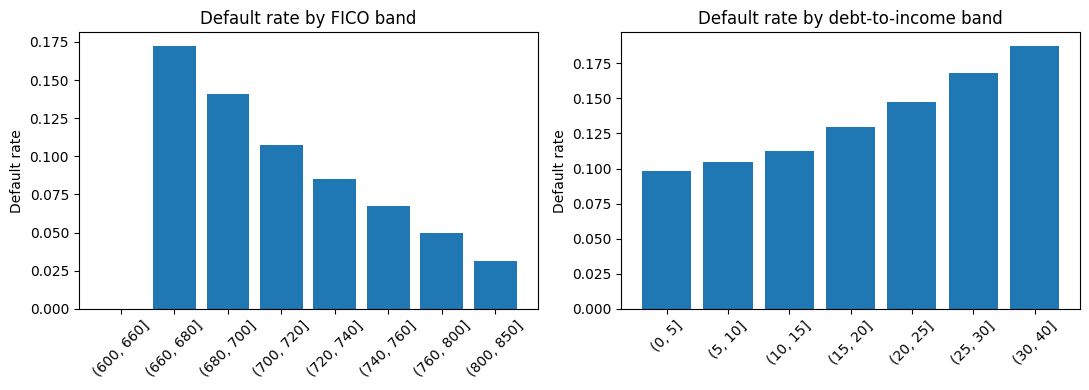

In [6]:
fico_table = default_rate_by(train, "fico", bins=[600, 660, 680, 700, 720, 740, 760, 800, 850])
dti_table = default_rate_by(train, "dti", bins=[0, 5, 10, 15, 20, 25, 30, 40, 100])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(fico_table.index.astype(str), fico_table["default_rate"])
axes[0].set_title("Default rate by FICO band")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(dti_table.index.astype(str), dti_table["default_rate"])
axes[1].set_title("Default rate by debt-to-income band")
axes[1].tick_params(axis="x", rotation=45)
for ax in axes:
    ax.set_ylabel("Default rate")
fig.tight_layout()
fig.savefig(config.FIGURES / "02_default_rate_by_fico_dti.png", dpi=150)
fico_table

In [7]:
for col in CATEGORICAL_FEATURES:
    display(default_rate_by(train, col).sort_values("loans", ascending=False).head(10))

,loans,default_rate,share_of_loans
home_ownership,,,
MORTGAGE,126172,0.1085,0.4700
RENT,117269,0.1526,0.4368
OWN,24877,0.1383,0.0927
OTHER,99,0.2222,0.0004
NONE,28,0.1786,0.0001
ANY,1,0.0000,0.0000


,loans,default_rate,share_of_loans
verification_status,,,
Not Verified,105805,0.1184,0.3941
Verified,83892,0.1402,0.3125
Source Verified,78749,0.1368,0.2934


,loans,default_rate,share_of_loans
purpose,,,
debt_consolidation,151928,0.1360,0.5660
credit_card,63558,0.1108,0.2368
home_improvement,14766,0.1121,0.0550
other,14758,0.1543,0.0550
major_purchase,6013,0.1106,0.0224
small_business,4019,0.2137,0.0150
car,3342,0.0975,0.0124
medical,3013,0.1689,0.0112
moving,2026,0.1876,0.0075


**Things worth spotting:**

- **FICO** should fall steadily from left to right: the strongest single application variable in most consumer credit.
- **Verification status** often goes the "wrong" way: verified incomes default *more*. That's not because verification causes default. Lending Club chose to verify the applicants it was already worried about, so "verified" partly flags risk. This is **selection bias**, and it's a good example of why a coefficient isn't a causal effect.
- **Purpose:** small business loans are usually riskier than credit card refinancing.

## Why this motivates v2

Logistic regression assumes each feature moves the **log-odds** of default in a straight line. Some relationships aren't straight (debt-to-income often flattens, employment length barely matters).
In v2 we'll **bin** each feature and replace the bin with its **Weight of Evidence**, which handles curves while keeping the model explainable, as banks' scorecards do.

In [8]:
numeric_view = pd.DataFrame({
    col: [train[col].median(), train.loc[train["default"] == 1, col].median(), train.loc[train["default"] == 0, col].median()]
    for col in NUMERIC_FEATURES
}, index=["median_all", "median_defaulted", "median_paid"]).T
numeric_view

,median_all,median_defaulted,median_paid
loan_amnt,"10,000.0000","10,000.0000","10,000.0000"
log_annual_inc,11.0021,10.8590,11.0104
loan_to_income,0.1806,0.2000,0.1778
dti,16.3500,18.1200,16.0900
fico,692.0000,682.0000,692.0000
emp_length_years,6.0000,6.0000,6.0000
credit_history_years,14.1711,13.5797,14.3299
inq_last_6mths,0.0000,1.0000,0.0000
delinq_2yrs,0.0000,0.0000,0.0000
open_acc,10.0000,10.0000,10.0000
